# Лабораторна робота №2
## «Теорія розпізнавання образів та класифікації в системах ШІ»
**Тема:** Попередня обробка даних та формування простору ознак для задачі розпізнавання образів

**Проєкт команди:** *Банківський скролинг* — прогноз відтоку клієнтів банку (Churn Modelling)
**Склад команди:** *Сотниченко Артем*;
 *Вірченко Богдан*; 
 *Микитиа Тринько*;
**Група:** *[КН23002б]*



## 1. Підготовка середовища та конфігурація


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

#Конфігурація 
DATA_PATH = "Churn_Modelling.csv"
TARGET = "Exited"
ID_COLS = ["RowNumber", "CustomerId", "Surname"]   # ідентифікатори — не несуть класифікаційної інформації
RANDOM_STATE = 42
TEST_SIZE = 0.2          # розбиття 80/20
MISSING_FRAC = 0.05      # частка штучних пропусків
CORR_TARGET_THR = 0.02   # поріг відбору ознак: |r з цільовою| < порогу => ознака слабка
CORR_PAIR_THR = 0.90     # поріг мультиколінеарності: |r| між ознаками > порогу => надлишкова
IQR_K = 1.5

## 2. Постановка задачі та шкали вимірювання

**Задача:** бінарна класифікація supervised learning Цільова змінна Exited: 1 - клієнт пішов, 0 - залишився
**Мета:** передбачити відтік клієнтів банку за їхніми характеристиками

| Ознака | Шкала вимірювання | Кодування / обробка |
|---|---|---|
| `Geography` | номінальна | One-Hot Encoding |
| `Gender` | номінальна (бінарна) | Label Encoding (0/1) |
| `HasCrCard`, `IsActiveMember` | номінальні (бінарні) | вже 0/1, не масштабуються |
| `NumOfProducts` | порядкова | залишається числовою, масштабується |
| `CreditScore` | інтервальна (умовний рейтинг) | викиди IQR, масштабування |
| `Age`, `Tenure`, `Balance`, `EstimatedSalary` | відносна (є природний нуль) | Age - викиди IQR, масштабування |
| `RowNumber`, `CustomerId`, `Surname` | ідентифікатори | видаляються |

## 3. Розвідувальний аналіз даних (EDA)

In [2]:
df_raw = pd.read_csv(DATA_PATH)

print("Розмір датасету (об'єктів, ознак):", df_raw.shape)
print("\nТипи ознак:")
df_raw.info()

Розмір датасету (об'єктів, ознак): (10000, 14)

Типи ознак:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [3]:
display(df_raw.head(3))
display(df_raw.describe().T.round(2))

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1


,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5000.50,2886.90,1.00,2500.75,5000.50,7500.25,10000.00
CustomerId,10000.0,15690940.57,71936.19,15565701.00,15628528.25,15690738.00,15753233.75,15815690.00
CreditScore,10000.0,650.53,96.65,350.00,584.00,652.00,718.00,850.00
Age,10000.0,38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,10000.0,5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,10000.0,76485.89,62397.41,0.00,0.00,97198.54,127644.24,250898.09
NumOfProducts,10000.0,1.53,0.58,1.00,1.00,1.00,2.00,4.00
HasCrCard,10000.0,0.71,0.46,0.00,0.00,1.00,1.00,1.00
IsActiveMember,10000.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00
EstimatedSalary,10000.0,100090.24,57510.49,11.58,51002.11,100193.92,149388.25,199992.48


In [4]:
print("Пропуски по стовпцях:")
print(df_raw.isnull().sum()[lambda s: s > 0] if df_raw.isnull().any().any() else "пропусків немає")
print("\nКількість дублікатів рядків:", df_raw.duplicated().sum())
print("Унікальних CustomerId:", df_raw["CustomerId"].nunique(), "із", len(df_raw))

print("\nРозподіл цільової змінної:")
print(df_raw[TARGET].value_counts())
print(df_raw[TARGET].value_counts(normalize=True).round(3))

Пропуски по стовпцях:
пропусків немає

Кількість дублікатів рядків: 0
Унікальних CustomerId: 10000 із 10000

Розподіл цільової змінної:
Exited
0    7963
1    2037
Name: count, dtype: int64
Exited
0    0.796
1    0.204
Name: proportion, dtype: float64


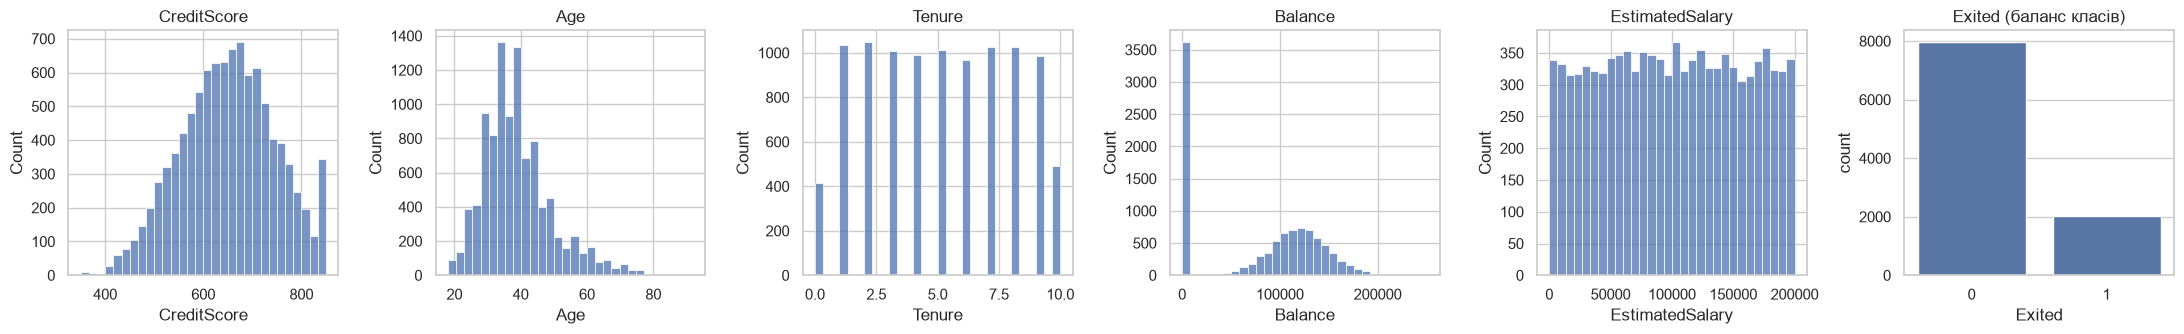

In [5]:
num_features = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"]
fig, axes = plt.subplots(1, 6, figsize=(22, 3.5))
for ax, col in zip(axes, num_features):
    sns.histplot(df_raw[col], bins=30, ax=ax)
    ax.set_title(col)
sns.countplot(x=TARGET, data=df_raw, ax=axes[5])
axes[5].set_title("Exited (баланс класів)")
plt.tight_layout()
plt.show()

**Висновок з EDA.** Клас Exited = 1 є міноритарним приблизно пята частина вибірки, тобто класи незбалансовані: одна лише accuracy буде необєктивною, тому далі аналізуємо також Precision, Recall та f1 для класу 1
Дублікатів і пропусків у вихідних даних немає тоuj дублікати видаляємо на всяк випадок, а пропуски створюємо штучно 


## 4. Видалення дублікатів та ідентифікаторів. Штучні пропуски

Вихідний датасет не має пропусків Щоб виконати вимогу методички штучно створюємо 5 % пропусків у Age (числова) та Geography (категоріальна) 

Змінна df_orig зберігає оригінальні значення - вона потрібна длч порівняння до/після і для фінального очищеного датасету.

In [6]:
# 1. Дублікати перевіряємо ДО видалення ідентифікаторів та ідентифікатори
df_orig = (df_raw.drop_duplicates()
                 .drop(columns=ID_COLS, errors="ignore")
                 .reset_index(drop=True))
print("Після очищення:", df_orig.shape)

# 2. Штучні пропуски на копії; оригінал лишається незайманим
df = df_orig.copy()
idx_age = df.sample(frac=MISSING_FRAC, random_state=RANDOM_STATE).index
idx_geo = df.sample(frac=MISSING_FRAC, random_state=RANDOM_STATE + 1).index
df.loc[idx_age, "Age"] = np.nan
df.loc[idx_geo, "Geography"] = np.nan

print("\nПропуски у даних після внесення:")
print(df.isna().sum()[lambda s: s > 0])

Після очищення: (10000, 11)

Пропуски у даних після внесення:
Geography    500
Age          500
dtype: int64


## 5. Розбиття на навчальну та тестову вибірки (80/20, stratify)

Розбиття виконується першим до будь якої імпутації обчислення меж IQR, відбору ознак чи масштабування Далі все, що вчиться на даних буде вчиться тільки на X_train

In [7]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
X_train, X_test = X_train.copy(), X_test.copy()

print(f"train: {X_train.shape}, test: {X_test.shape}")
print("Частка Exited=1 | train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))
print("Пропусків у train/test:", X_train.isna().sum().sum(), "/", X_test.isna().sum().sum())

train: (8000, 10), test: (2000, 10)
Частка Exited=1 | train: 0.204 | test: 0.203
Пропусків у train/test: 817 / 183


## 6. Обробка пропущених значень (два методи, порівняння)

Усі імпутери навчаються fit лише на X_train

* **Age:** середнє vs медіана
* **Geography:** мода vs окрема категорія Unknown

,Оригінал (до внесення пропусків),Середнє,Медіана
mean,38.947,38.973,38.872
median,37.000,38.000,37.000
std,10.527,10.295,10.304


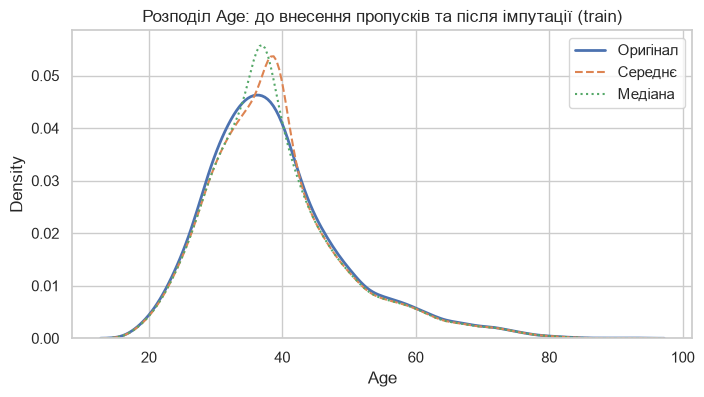

In [8]:
# Age порівняння середнього та медіани fit тільки на train
imp_mean = SimpleImputer(strategy="mean").fit(X_train[["Age"]])
imp_median = SimpleImputer(strategy="median").fit(X_train[["Age"]])

age_true = df_orig.loc[X_train.index, "Age"]   # справжні значення (лише для порівняння)
age_mean = pd.Series(imp_mean.transform(X_train[["Age"]]).ravel(), index=X_train.index)
age_median = pd.Series(imp_median.transform(X_train[["Age"]]).ravel(), index=X_train.index)

cmp_age = pd.DataFrame({
    "Оригінал (до внесення пропусків)": age_true,
    "Середнє": age_mean,
    "Медіана": age_median,
}).agg(["mean", "median", "std"]).round(3)
display(cmp_age)

plt.figure(figsize=(8, 4))
sns.kdeplot(age_true, label="Оригінал", lw=2)
sns.kdeplot(age_mean, label="Середнє", ls="--")
sns.kdeplot(age_median, label="Медіана", ls=":")
plt.title("Розподіл Age: до внесення пропусків та після імпутації (train)")
plt.legend()
plt.show()

In [9]:
# Geography: мода vs категорія Unknown
imp_mode = SimpleImputer(strategy="most_frequent").fit(X_train[["Geography"]])
imp_const = SimpleImputer(strategy="constant", fill_value="Unknown").fit(X_train[["Geography"]])

geo_true = df_orig.loc[X_train.index, "Geography"]
geo_mode = pd.Series(imp_mode.transform(X_train[["Geography"]]).ravel(), index=X_train.index)
geo_const = pd.Series(imp_const.transform(X_train[["Geography"]]).ravel(), index=X_train.index)

cmp_geo = pd.DataFrame({
    "Оригінал": geo_true.value_counts(normalize=True),
    "Мода": geo_mode.value_counts(normalize=True),
    "Unknown": geo_const.value_counts(normalize=True),
}).round(3)
display(cmp_geo)

,Оригінал,Мода,Unknown
France,0.499,0.524,0.472
Germany,0.251,0.239,0.239
Spain,0.250,0.237,0.237
Unknown,NaN,NaN,0.051


**Обґрунтування вибору.**
* Age: розподіл віку має правосторонню асиметрію бо старші клієнти, тому середнє іде за хвостом, а медіана стоййка до викидів
* Geography: мода зберігає структуру частот і не створює зайву dummy колонку Категорія Unknown додала б ознаку без реальної інформації бо пропуски штучні й випадкові

In [10]:
# Застосовуємо вибрані імпутери fit був на train до test лише transform
final_age_imp = SimpleImputer(strategy="median").fit(X_train[["Age"]])
final_geo_imp = SimpleImputer(strategy="most_frequent").fit(X_train[["Geography"]])

for part in (X_train, X_test):
    part["Age"] = final_age_imp.transform(part[["Age"]]).ravel()
    part["Geography"] = final_geo_imp.transform(part[["Geography"]]).ravel()

print("Пропуски після обробки (train / test):", X_train.isna().sum().sum(), "/", X_test.isna().sum().sum())
print("Медіана Age, обчислена на train:", final_age_imp.statistics_[0])
print("Мода Geography, обчислена на train:", final_geo_imp.statistics_[0])

Пропуски після обробки (train / test): 0 / 0
Медіана Age, обчислена на train: 37.0
Мода Geography, обчислена на train: France


## 7. Кодування категоріальних ознак

* Gender - номінальна бінарна - **Label Encoding** (Female = 0, Male = 1)
* Geography - номінальна з 3 значеннями - **One-Hot Encoding** з drop_first=True уникаємо фіктивних змінних. Колонки test вирівнюються за train

Після цього фіксуємо сирий» варіант X_*_raw: закодовані ознаки без обробки викидів відбору ознак і масштабування. Мінімум, потрібний для запуску k-NN пропуски заповнені текст закодований, однаковий для обох варіантів того подальше порівняння ізолює вплив викидів, відбору ознак і масштабування

In [11]:
def encode(X_tr, X_te):
    X_tr, X_te = X_tr.copy(), X_te.copy()
    gender_map = {"Female": 0, "Male": 1}
    X_tr["Gender"] = X_tr["Gender"].map(gender_map)
    X_te["Gender"] = X_te["Gender"].map(gender_map)

    X_tr = pd.get_dummies(X_tr, columns=["Geography"], drop_first=True, dtype=int)
    X_te = pd.get_dummies(X_te, columns=["Geography"], drop_first=True, dtype=int)
    X_te = X_te.reindex(columns=X_tr.columns, fill_value=0)   # однакові колонки
    return X_tr, X_te

X_train_enc, X_test_enc = encode(X_train, X_test)

# Сирі дані для порівняння
X_train_raw, X_test_raw = X_train_enc.copy(), X_test_enc.copy()

print("Колонки після кодування:", list(X_train_enc.columns))
display(X_train_enc.head(3))

Колонки після кодування: ['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain']


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain
2151,753,1,57.0,7,0.00,1,1,0,159475.08,0,0
8392,739,1,32.0,3,102128.27,1,1,0,63981.37,1,0
5006,755,0,37.0,0,113865.23,2,1,1,117396.25,1,0


## 8. Виявлення та обробка викидів (правило IQR)

Межі Q1 − 1.5·IQR; Q3 + 1.5·IQR обчислюються на train і застосовуються до train та test
Обрані ознаки: Age та CreditScore

Сapping обмеження значень по межах а не видалення. Видалення клієнтів це втрата даних, а для класифікації відтоку вікові викиди літні клієнти - реальні й потенційно інформативні обєкти

In [12]:
OUT_COLS = ["Age", "CreditScore"]

def iqr_bounds(s, k=IQR_K):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1, q3, iqr, q1 - k * iqr, q3 + k * iqr

X_train_proc, X_test_proc = X_train_enc.copy(), X_test_enc.copy()

rows = []
for c in OUT_COLS:
    q1, q3, iqr, lo, hi = iqr_bounds(X_train_proc[c])
    n_tr = ((X_train_proc[c] < lo) | (X_train_proc[c] > hi)).sum()
    n_te = ((X_test_proc[c] < lo) | (X_test_proc[c] > hi)).sum()
    rows.append({"Ознака": c, "Q1": q1, "Q3": q3, "IQR": iqr,
                 "Нижня межа": lo, "Верхня межа": hi,
                 "Викидів у train": n_tr, "Викидів у test": n_te})
    # capping: межі з train
    X_train_proc[c] = X_train_proc[c].clip(lo, hi)
    X_test_proc[c] = X_test_proc[c].clip(lo, hi)

bounds_table = pd.DataFrame(rows).set_index("Ознака").round(2)
display(bounds_table)

,Q1,Q3,IQR,Нижня межа,Верхня межа,Викидів у train,Викидів у test
Ознака,,,,,,,
Age,32.0,43.0,11.0,15.5,59.5,411,98
CreditScore,584.0,717.0,133.0,384.5,916.5,14,2


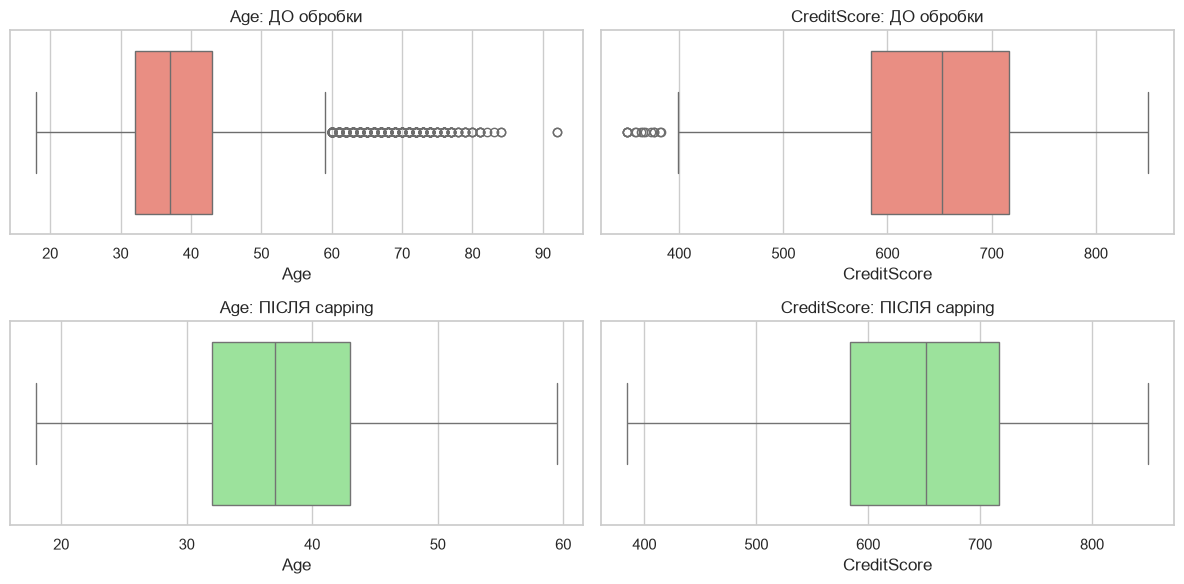

In [13]:
# Boxplot до та після capping 
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for j, c in enumerate(OUT_COLS):
    sns.boxplot(x=X_train_enc[c], ax=axes[0, j], color="salmon")
    axes[0, j].set_title(f"{c}: ДО обробки")
    sns.boxplot(x=X_train_proc[c], ax=axes[1, j], color="lightgreen")
    axes[1, j].set_title(f"{c}: ПІСЛЯ capping")
plt.tight_layout()
plt.show()

## 9. Відбір ознак (фільтраційний метод, аналіз кореляції)

Кореляції обчислюються на train. Правила відбору:
1. З кожної пари ознак із |r| > 0.9 видаляється та що слабше корелює з цільовою змінною 
2. Видаляються ознаки зі слабким звязком із цільовою змінною: |r| < 0.02. Кореляція Пірсона з бінарною ціллю це point biserial коефіцієнт
3. Dummy-колонки Geography_ не розривають: група зберігається, якщо хоча б одна з колонок проходить фільтр

Раніше також видалено структурно надлишкові ознаки: RowNumber, CustomerId, Surname 

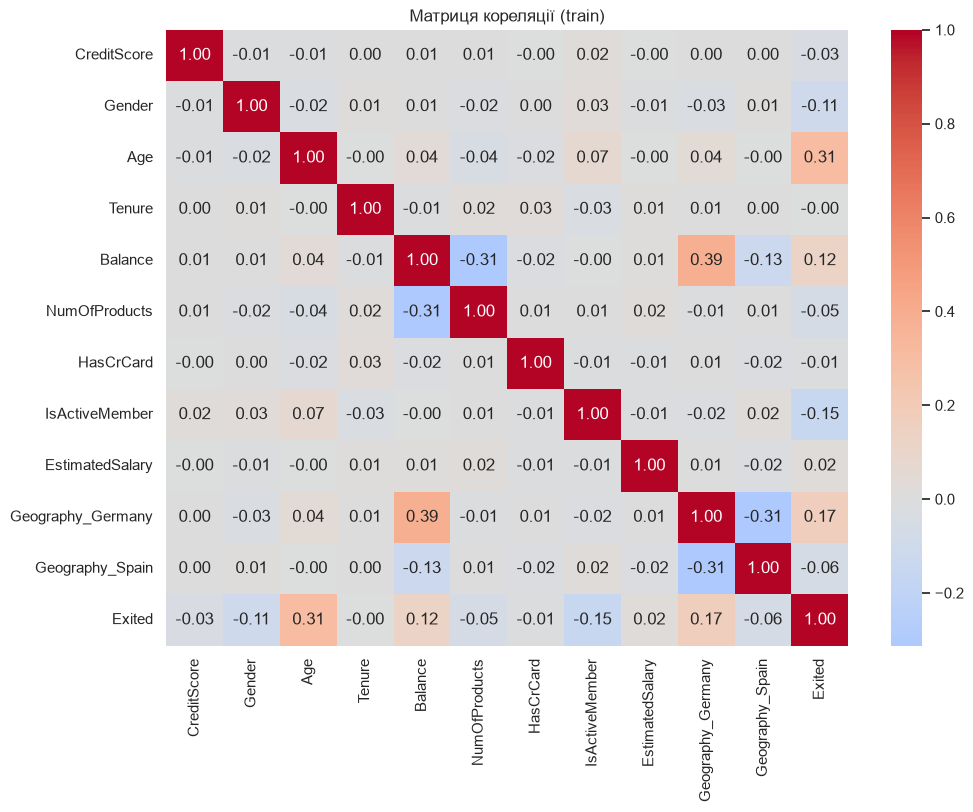

,r з Exited
Age,0.309
Geography_Germany,0.174
IsActiveMember,-0.152
Balance,0.121
Gender,-0.106
Geography_Spain,-0.057
NumOfProducts,-0.054
CreditScore,-0.033
EstimatedSalary,0.020
HasCrCard,-0.015


In [14]:
train_full = pd.concat([X_train_proc, y_train], axis=1)
corr = train_full.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Матриця кореляції (train)")
plt.show()

corr_target = corr[TARGET].drop(TARGET)
display(corr_target.sort_values(key=abs, ascending=False).round(3).to_frame("r з Exited"))

In [15]:
drop_cols = set()

# Правило 1 сильно корельовані пари ознак
feat_corr = X_train_proc.corr().abs()
for i, a in enumerate(feat_corr.columns):
    for b in feat_corr.columns[i + 1:]:
        if feat_corr.loc[a, b] > CORR_PAIR_THR:
            worse = a if abs(corr_target[a]) < abs(corr_target[b]) else b
            drop_cols.add(worse)
            print(f"Пара ({a}, {b}): |r| = {feat_corr.loc[a, b]:.2f} -> видаляємо {worse}")
if not drop_cols:
    print(f"Пар із |r| > {CORR_PAIR_THR}: немає (мультиколінеарності немає).")

# Правило 2 слабкий звязок із ціллю
weak = set(corr_target[corr_target.abs() < CORR_TARGET_THR].index)

# Правило 3 не розриваємо групу Geography_*
geo_cols = [c for c in X_train_proc.columns if c.startswith("Geography_")]
if any(c not in weak for c in geo_cols):
    weak -= set(geo_cols)

drop_cols |= weak
print(f"\nВидаляємо ознаки (|r з ціллю| < {CORR_TARGET_THR} або надлишкові):", sorted(drop_cols))
if not drop_cols:
    print("УВАГА: жодну ознаку не видалено. Збільшіть CORR_TARGET_THR і опоясніть вибір у звіті.")
selected = [c for c in X_train_proc.columns if c not in drop_cols]
X_train_sel = X_train_proc[selected].copy()
X_test_sel = X_test_proc[selected].copy()
print("Залишені ознаки:", selected)

Пар із |r| > 0.9: немає (мультиколінеарності немає).

Видаляємо ознаки (|r з ціллю| < 0.02 або надлишкові): ['HasCrCard', 'Tenure']
Залишені ознаки: ['CreditScore', 'Gender', 'Age', 'Balance', 'NumOfProducts', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain']


## 10. Масштабування числових ознак

Обрано Z-стандартизацію StandardScaler вона не привязує діапазон до крайніх значень вибірки як Min-Max, чутливого до мінімуму/максимуму підходить для метричних алгоритмів k-NN і є стандартом для подальших лінійних моделей курсу
fit - лише на X_train до X_test застосовується transform. Масштабуються тільки неперервні/числові ознаки бінарні та dummy-колонки лишаються так як є

In [16]:
candidate_num = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
num_cols = [c for c in candidate_num if c in X_train_sel.columns]
print("Масштабуємо:", num_cols)

scaler = StandardScaler().fit(X_train_sel[num_cols])          # fit лише на train

X_train_scaled = X_train_sel.copy()
X_test_scaled = X_test_sel.copy()
X_train_scaled[num_cols] = scaler.transform(X_train_sel[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test_sel[num_cols])   # тільки transform

display(X_train_scaled[num_cols].describe().loc[["mean", "std"]].round(3))

Масштабуємо: ['CreditScore', 'Age', 'Balance', 'NumOfProducts', 'EstimatedSalary']


,CreditScore,Age,Balance,NumOfProducts,EstimatedSalary
mean,-0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


## 11. Базовий класифікатор k-NN: «сирі» vs «оброблені» дані

* **RAW** - закодовані дані без capping, відбору ознак і масштабування
* **PROCESSED** - після capping викидів, кореляційного відбору та стандартизації

Модель однакова k = 5, тестова вибірка однакова

In [17]:
def evaluate(Xtr, Xte, name, k=5):
    model = KNeighborsClassifier(n_neighbors=k).fit(Xtr, y_train)
    pred = model.predict(Xte)
    return pred, {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
    }

pred_raw, m_raw = evaluate(X_train_raw, X_test_raw, "RAW")
pred_proc, m_proc = evaluate(X_train_scaled, X_test_scaled, "PROCESSED")

results = pd.DataFrame({"RAW": m_raw, "PROCESSED": m_proc}).T.round(4)
display(results)

majority_acc = max(y_test.mean(), 1 - y_test.mean())
print(f"Accuracy тривіального класифікатора (завжди клас 0): {majority_acc:.4f}")

,Accuracy,Precision,Recall,F1
RAW,0.764,0.2556,0.0835,0.1259
PROCESSED,0.844,0.6792,0.4423,0.5357


Accuracy тривіального класифікатора (завжди клас 0): 0.7965


In [18]:
print("=== RAW ===")
print(classification_report(y_test, pred_raw, target_names=["Залишився (0)", "Пішов (1)"], zero_division=0))
print("=== PROCESSED ===")
print(classification_report(y_test, pred_proc, target_names=["Залишився (0)", "Пішов (1)"], zero_division=0))

=== RAW ===
               precision    recall  f1-score   support

Залишився (0)       0.80      0.94      0.86      1593
    Пішов (1)       0.26      0.08      0.13       407

     accuracy                           0.76      2000
    macro avg       0.53      0.51      0.49      2000
 weighted avg       0.69      0.76      0.71      2000

=== PROCESSED ===
               precision    recall  f1-score   support

Залишився (0)       0.87      0.95      0.91      1593
    Пішов (1)       0.68      0.44      0.54       407

     accuracy                           0.84      2000
    macro avg       0.77      0.69      0.72      2000
 weighted avg       0.83      0.84      0.83      2000



In [19]:
# Додатково: Min-Max замість Z-стандартизації ті самі кроки fit лише на train
mm = MinMaxScaler().fit(X_train_sel[num_cols])
X_train_mm, X_test_mm = X_train_sel.copy(), X_test_sel.copy()
X_train_mm[num_cols] = mm.transform(X_train_sel[num_cols])
X_test_mm[num_cols] = mm.transform(X_test_sel[num_cols])
_, m_mm = evaluate(X_train_mm, X_test_mm, "MINMAX")

results_ext = pd.DataFrame({"RAW": m_raw, "PROCESSED (Z-score)": m_proc,
                            "PROCESSED (Min-Max)": m_mm}).T.round(4)
display(results_ext)

,Accuracy,Precision,Recall,F1
RAW,0.764,0.2556,0.0835,0.1259
PROCESSED (Z-score),0.844,0.6792,0.4423,0.5357
PROCESSED (Min-Max),0.832,0.6524,0.3735,0.4750


## 12. Збереження підготовлених даних для лабораторної №3

* Churn_train_prepared.csv, Churn_test_prepared.csv - підготовлені вибірки закодовані, з обробленими викидами, відібраними ознаками, стандартизовані; з колонкою Exited. Саме їх використовуємо в лабораторній №3 для k-NN
* Churn_Modelling_Cleaned.csv - очищений датасет з оригінальними значеннями без дублікатів та ідентифікаторів та без штучних пропусків але не масштабований

In [20]:
train_out = X_train_scaled.copy(); train_out[TARGET] = y_train.values
test_out = X_test_scaled.copy();  test_out[TARGET] = y_test.values
train_out.to_csv("Churn_train_prepared.csv", index=False)
test_out.to_csv("Churn_test_prepared.csv", index=False)

cleaned = df_orig.copy()
cleaned["Gender"] = cleaned["Gender"].map({"Female": 0, "Male": 1})
cleaned = pd.get_dummies(cleaned, columns=["Geography"], drop_first=True, dtype=int)
cleaned.to_csv("Churn_Modelling_Cleaned.csv", index=False)

print("Збережено:", train_out.shape, test_out.shape, cleaned.shape)

Збережено: (8000, 10) (2000, 10) (10000, 12)


## Висновки 

**1. Пропуски.** Вихідний датасет не мав пропусків; 5 % значень Age та Geography створено штучно. Для Age порівняно середнє та медіану обрано медіану через асиметрію розподілу, для Geography - моду та категорію Unknown . Усі імпутери навчено лише на train.

**2. Викиди.** За правилом IQR перевірено Age та CreditScore. Застосовано capping замість видалення, щоб не втрачати обєкти.

**3. Кодування.** Gender - Label Encoding, Geography - One-Hot drop_first=True, колонки test вирівняно за train

**4. Відбір ознак.** Видалено ідентифікатори та ознаки, виявлені кореляційним фільтром перелік виведено в розділі 9. Пар зі збіжністю |r| > 0.9 перевірено окремо

**5. Data leakage.** Імпутери, межі IQR, відбір ознак і StandardScaler обчислено лише за X_train; до X_test застосовано тільки transform / clip із параметрами train

In [21]:
r, p = results.loc["RAW"], results.loc["PROCESSED"]
d = p - r

def trend(x):
    return "зросла" if x > 1e-9 else ("знизилась" if x < -1e-9 else "не змінилась")

text = (
    "**6. Порівняння k-NN (k = 5).**\n\n"
    f"* **RAW:** Accuracy = {r['Accuracy']:.4f}, Precision = {r['Precision']:.4f}, "
    f"Recall = {r['Recall']:.4f}, F1 = {r['F1']:.4f}.\n"
    f"* **PROCESSED:** Accuracy = {p['Accuracy']:.4f}, Precision = {p['Precision']:.4f}, "
    f"Recall = {p['Recall']:.4f}, F1 = {p['F1']:.4f}.\n"
    f"* Зміна після обробки: Accuracy {trend(d['Accuracy'])} ({d['Accuracy']:+.4f}), "
    f"Precision {trend(d['Precision'])} ({d['Precision']:+.4f}), "
    f"Recall {trend(d['Recall'])} ({d['Recall']:+.4f}), "
    f"F1 {trend(d['F1'])} ({d['F1']:+.4f}).\n\n"
    "**Пояснення.** k-NN використовує Евклідову відстань, тому ознаки з великими числовими значеннями "
    "(`Balance`, `EstimatedSalary` ~ 10^5) домінують над ознаками з малими (`Age` ~ 10^1, бінарні ознаки). "
    "Стандартизація вирівнює внесок ознак у відстань, а відбір ознак прибирає шумові змінні зі слабким "
    "зв'язком із ціллю.\n\n"
    f"**Про метрики.** Через дисбаланс класів тривіальний класифікатор «ніхто не пішов» дав би Accuracy = "
    f"{majority_acc:.4f}, тому Accuracy тут малоінформативна; ключовими є Recall та F1 для класу `Exited = 1`. "
    f"Для класу 1 F1 {trend(d['F1'])} з {r['F1']:.4f} до {p['F1']:.4f}.\n\n"
    "**Загальний висновок:** попередня обробка (передусім масштабування) є важливою для метричних "
    "алгоритмів класифікації. Підготовлені train/test-файли збережено для лабораторної роботи №3"
)
display(Markdown(text))

**6. Порівняння k-NN (k = 5).**

* **RAW:** Accuracy = 0.7640, Precision = 0.2556, Recall = 0.0835, F1 = 0.1259.
* **PROCESSED:** Accuracy = 0.8440, Precision = 0.6792, Recall = 0.4423, F1 = 0.5357.
* Зміна після обробки: Accuracy зросла (+0.0800), Precision зросла (+0.4236), Recall зросла (+0.3588), F1 зросла (+0.4098).

**Пояснення.** k-NN використовує Евклідову відстань, тому ознаки з великими числовими значеннями (`Balance`, `EstimatedSalary` ~ 10^5) домінують над ознаками з малими (`Age` ~ 10^1, бінарні ознаки). Стандартизація вирівнює внесок ознак у відстань, а відбір ознак прибирає шумові змінні зі слабким зв'язком із ціллю.

**Про метрики.** Через дисбаланс класів тривіальний класифікатор «ніхто не пішов» дав би Accuracy = 0.7965, тому Accuracy тут малоінформативна; ключовими є Recall та F1 для класу `Exited = 1`. Для класу 1 F1 зросла з 0.1259 до 0.5357.

**Загальний висновок:** попередня обробка (передусім масштабування) є важливою для метричних алгоритмів класифікації. Підготовлені train/test-файли збережено для лабораторної роботи №3